# LightNav-0: MicroDuck понимает команды и ориентируется в разных комнатах

Этот Notebook (интерактивное руководство) соответствует 8-му дню 8-дневного плана обучения. Используется готовая модель: обучения нет, плата не подключается.
LightNav-0 на GPU читает изображение от первого лица и языковую команду и предсказывает локальную траекторию;
MPC (model predictive control) преобразует траекторию в команды скорости; готовая политика ходьбы управляет 14 суставами утёнка, MuJoCo выполняет контакт и физическую симуляцию.

Последовательно запускаются официальный многокомнатный дом, самостоятельно собранная гостиная и собранный коридор. Для каждой сцены создаются видео, журнал предсказаний и график траектории.
Для удобного повторения на занятии симуляция во время инференса приостанавливается, видео воспроизводится в симуляционном времени; таблица задержек фиксирует реальное время инференса.
Низкоуровневая ходьба использует CPU-интерфейс официального ONNX Runtime.


## 1. Окружение и пути по умолчанию

На Ubuntu в качестве ядра используется окружение симулятора. Как подготовить окружение впервые, см.
[пояснения к сопутствующему коду](../02-executable-code/lightnav-learning/README.md).
Значения по умолчанию соответствуют ресурсам рабочей станции этой темы; на другой машине достаточно изменить пути ниже или соответствующие переменные окружения.
Веса модели и видео сохраняются вне репозитория; повторный запуск перезаписывает последний результат для той же сцены.

In [1]:
import os
os.environ.setdefault("MUJOCO_GL", "egl")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("OMP_NUM_THREADS", "4")
import json
from pathlib import Path
import subprocess
import shutil
import sys
import numpy as np
from IPython.display import display, Image, Video, Markdown
get_ipython().run_line_magic("matplotlib", "inline")

def locate_topic():
    configured = os.getenv("MICRODUCK_TOPIC_ROOT")
    if configured:
        return Path(configured).expanduser().resolve()
    for base in (Path.cwd(), *Path.cwd().parents):
        if (base / "02-可运行代码" / "lightnav-learning").is_dir():  # каталог upstream, не переводить
            return base
    raise FileNotFoundError("Запустите ядро из каталога 03-Notebook этой темы или задайте MICRODUCK_TOPIC_ROOT.")

TOPIC = locate_topic()
LIGHTNAV_ROOT = Path(os.getenv("LIGHTNAV_ROOT", str(Path.home() / "projects/LightNav-0")))
MODEL_ENV = Path(os.getenv("LIGHTNAV_MODEL_ENV", "/data/Data14TB/envs/lightnav-0"))
MODEL_PATH = Path(os.getenv("LIGHTNAV_MODEL_PATH", "/data/Data14TB/checkpoints/LightNav-0"))
ROBOT_MODEL = Path(os.getenv("LIGHTNAV_ROBOT_MODEL", str(Path.home() / "workspaces/microduck_rl/src/mjlab_microduck/robot/microduck/robot_allcollisions.xml")))
WALKING_POLICY = Path(os.getenv("LIGHTNAV_WALKING_POLICY", "/data/Data14TB/checkpoints/microduck-navigation/alpha_walking.onnx"))
OUTPUT = Path(os.getenv("LIGHTNAV_OUTPUT", "/data/Data14TB/lightnav-recordings/teaching/notebook"))
OUTPUT.mkdir(parents=True, exist_ok=True)
NOTEBOOK_DIR = TOPIC / "03-Notebook"
WEB_OUTPUT = NOTEBOOK_DIR / "outputs/lightnav_gpu"
WEB_OUTPUT.parent.mkdir(parents=True, exist_ok=True)
if WEB_OUTPUT.is_symlink():
    assert WEB_OUTPUT.resolve() == OUTPUT.resolve(), "Существующая ссылка вывода указывает на другое место, сначала проверьте."
    WEB_OUTPUT.unlink()
WEB_OUTPUT.mkdir(exist_ok=True)
for resource in (LIGHTNAV_ROOT / "mujoco_demo/vln_mujoco", MODEL_ENV / "bin/lightnav-serve", MODEL_PATH / "eval_config.json", ROBOT_MODEL, WALKING_POLICY):
    assert resource.exists(), f"Нет ресурса: {resource}"
sys.path.insert(0, str(LIGHTNAV_ROOT / "mujoco_demo"))
sys.path.insert(0, str(TOPIC / "02-可运行代码/lightnav-learning"))  # путь upstream, не переводить
from lightnav_lesson import ensure_model_server, build_scenes, make_robot, camera_image, decode_response, run_episode
print("Проверка ресурсов пройдена; выходной каталог:", OUTPUT)
print("Используется готовая модель; обучение отключено; плата не нужна.")

资源检查通过；输出目录： /data/Data14TB/lightnav-recordings/teaching/notebook
本次使用已有模型；训练关闭；无需开发板。


## 2. Проверка вычислительного окружения

Модель навигации и симулятор используют отдельные окружения. Здесь проверяется только доступность и версии ПО, без вывода конкретной модели оборудования.

In [2]:
import importlib.metadata as metadata
import mujoco
import onnxruntime
gpu_check = subprocess.run(
    [str(MODEL_ENV / "bin/python"), "-c", "import torch,vllm,json; print(json.dumps({'cuda_available':torch.cuda.is_available(),'vllm':vllm.__version__}))"],
    capture_output=True, text=True, check=True,
)
compute = json.loads(gpu_check.stdout.strip().splitlines()[-1])
assert compute["cuda_available"], "Модели навигации нужен доступный GPU."
assert compute["vllm"] == "0.19.1", "Используйте окружение модели в закреплённой версии upstream."
print(compute)
print({name: metadata.version(name) for name in ("mujoco", "onnxruntime", "nbclient")})
print("Поток: изображение и язык → локальная траектория → команда скорости → действие суставов → новое изображение.")

{'cuda_available': True, 'vllm': '0.19.1'}
{'mujoco': '3.12.0', 'onnxruntime': '1.29.0', 'nbclient': '0.11.0'}
学习流程：图像与语言 → 局部轨迹 → 速度命令 → 关节动作 → 新图像。


## 3. Запуск модели навигации

vLLM загружает официальные предобученные веса. Уже работающий сервис переиспользуется; при первом запуске дождитесь окончания прогрева модели.
Если бэкенд недоступен, сразу выдаётся ошибка; подменять предсказания модели ручным путём не будем.

In [3]:
MODEL_PORT = int(os.getenv("LIGHTNAV_MODEL_PORT", "8050"))
service = ensure_model_server(MODEL_ENV, MODEL_PATH, OUTPUT, port=MODEL_PORT)
SERVER_URL = service["url"]
print(service)
config = json.loads((MODEL_PATH / "eval_config.json").read_text())
print("Представление действий: 10 плоских поз; каждая поза включает продольное смещение, боковое смещение и угол рысканья.")
print("Декодер действий поставляется с весами:", (MODEL_PATH / "action_tokenizer").is_dir())

{'url': 'ws://127.0.0.1:8050', 'state': 'existing listener'}
动作表示：10 个平面位姿；每个位姿包含前进距离、横向距离与偏航角。
动作解码器已随权重提供： True


## 4. Официальная сцена и две новые планировки

Официальный дом остаётся без изменений. Новые гостиная и коридор имеют переставленные стены, пол и мебель и используют реальные сеточные ресурсы из официальной сцены.
Гостиная проверяет подход к целевому объекту; коридор — влияние узкого пространства и боковой мебели на путь.
Положение цели используется только для измерения расстояния после запуска; в модель навигации оно не передаётся и для генерации команд управления не используется.

In [4]:
scenes = build_scenes(OUTPUT / "scenes")
for name, scene in scenes.items():
    print(name, "|", scene["instruction"])
print("Сцены и журнал изменений:", OUTPUT / "scenes/manifest.json")

official_apartment | Walk to the table on your left and stop.
living_room | Walk to the armchair in front of you and stop.
corridor | Go straight down the hallway to the potted plant and stop.
场景与修改记录： /data/Data14TB/lightnav-recordings/teaching/notebook/scenes/manifest.json


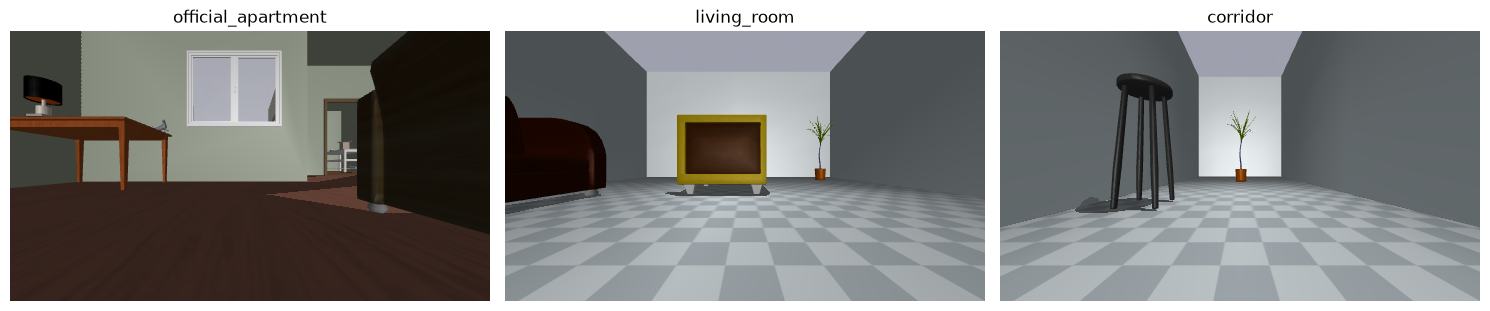

三个场景均已完成模型编译、第一视角渲染与 61 维观测检查。


In [5]:
import matplotlib.pyplot as plt
robots = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for axis, (name, scene) in zip(axes, scenes.items()):
    robot = make_robot(scene, ROBOT_MODEL, WALKING_POLICY)
    robots[name] = robot
    assert robot.model.nu == 14
    assert robot.policy.observation().shape == (61,)
    with mujoco.Renderer(robot.model, height=270, width=480) as renderer:
        axis.imshow(camera_image(robot, renderer))
    axis.set_title(name)
    axis.axis("off")
plt.tight_layout()
plt.show()
print("Для всех трёх сцен завершены компиляция модели, рендеринг от первого лица и проверка 61-мерных наблюдений.")

## 5. Разбор одного реального предсказания

Изображение и команда отправляются в модель через WebSocket.
Два канала пространственного указания передают цель и следующую позицию действия; RVQ-код действия (residual vector quantization) декодируется в плоскую траекторию 10×3.
Ниже напрямую выводятся текст ответа модели, флаг остановки и первые точки траектории.

In [6]:
import base64
import io
import websocket
from contextlib import closing
from PIL import Image as PILImage
robot = robots["living_room"]
with mujoco.Renderer(robot.model, height=270, width=480) as renderer:
    rgb = camera_image(robot, renderer)
buffer = io.BytesIO()
PILImage.fromarray(rgb).save(buffer, format="JPEG")
with closing(websocket.create_connection(SERVER_URL, timeout=90, http_no_proxy=["127.0.0.1", "localhost"])) as connection:
    connection.send(json.dumps({"action": "login", "data": {"clientId": "notebook-first-prediction"}}))
    assert json.loads(connection.recv())["data"]["rc"] == 0
    connection.send(json.dumps({"action": "next", "data": {"seq": 1, "image": base64.b64encode(buffer.getvalue()).decode(), "instruction": scenes["living_room"]["instruction"]}}))
    first_prediction, waypoints = decode_response(connection.recv(), 1)
print("Текст модели:", first_prediction.get("raw_text", ""))
print("Флаг остановки:", first_prediction["stop"], "; форма траектории:", waypoints.shape)
print("Первые 3 точки траектории:\\n", np.round(waypoints[:3], 3))

模型文本： <apos_839><opos_455><act_l0_16><act_l1_0><act_l2_208><|im_end|>
停止标志： False ；轨迹形状： (10, 3)
前 3 个轨迹点：
 [[0.146 0.039 0.262]
 [0.291 0.078 0.262]
 [0.437 0.117 0.262]]


## 6. Запуск трёх сцен и создание видео

Слева в каждом видео — вид от первого лица, который читает модель, справа — вид от третьего лица. Запуск идёт в симуляционном времени; во время инференса симуляция приостанавливается.
Контроллер отслеживает предсказанную траекторию, политика ходьбы управляет суставами с частотой 50 Гц.
Остановку вызывает выход модели; падение завершает эксперимент. Журнал выполнения сохраняет реальный результат и не выбирает успешные фрагменты автоматически.

In [7]:
EPISODE_SECONDS = float(os.getenv("LIGHTNAV_EPISODE_SECONDS", "24"))
reports = {}
def demonstrate(name):
    report, images = run_episode(name, scenes[name], ROBOT_MODEL, WALKING_POLICY, SERVER_URL, OUTPUT, seconds=EPISODE_SECONDS)
    reports[name] = report
    print(f"Сцена: {name}; причина остановки: {report['termination']}; число реальных предсказаний: {report['prediction_count']}")
    print(f"Длительность симуляции: {report['sim_seconds']:.2f} с; медиана задержки инференса: {report['median_latency_ms']:.1f} мс")
    print(f"Расстояние до центра цели: {report['initial_target_distance_m']:.2f} → {report['final_target_distance_m']:.2f} м")
    print(f"Полный отчёт: {name}_report.json; модель навигации работает на GPU.")
    shutil.copy2(report["video"], WEB_OUTPUT / f"{name}_latest.mp4")
    display(Video(f"outputs/lightnav_gpu/{name}_latest.mp4", embed=False, width=720,
                  html_attributes='controls style="max-width:100%;height:auto;"'))
    preview = OUTPUT / f"{name}_start_end.png"
    PILImage.fromarray(np.concatenate(images, axis=0)).save(preview)
    display(Image(filename=str(preview), width=720))
    return report
print("Параметры:", {"simulation_seconds": EPISODE_SECONDS, "prediction_hz": 4, "video_fps": 10})

参数： {'simulation_seconds': 24.0, 'prediction_hz': 4, 'video_fps': 10}


### Официальный дом


******************************************************************************
This program contains Ipopt, a library for large-scale nonlinear optimization.
 Ipopt is released as open source code under the Eclipse Public License (EPL).
         For more information visit https://github.com/coin-or/Ipopt
******************************************************************************



场景：official_apartment；停止原因：model_stop；真实预测次数：32
仿真时长：8.75 s；推理延迟中位数：100.7 ms
目标中心距离：2.95 → 2.10 m
完整报告：official_apartment_report.json；导航模型运行在 GPU［图形处理器］。


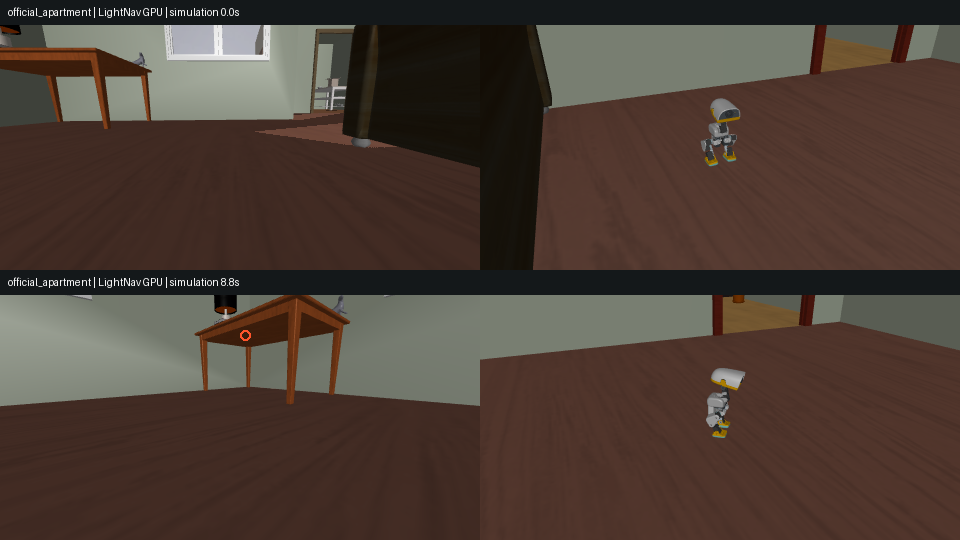

In [8]:
official_report = demonstrate("official_apartment")

### Собранная гостиная

场景：living_room；停止原因：model_stop；真实预测次数：12
仿真时长：3.75 s；推理延迟中位数：92.3 ms
目标中心距离：1.81 → 1.47 m
完整报告：living_room_report.json；导航模型运行在 GPU［图形处理器］。


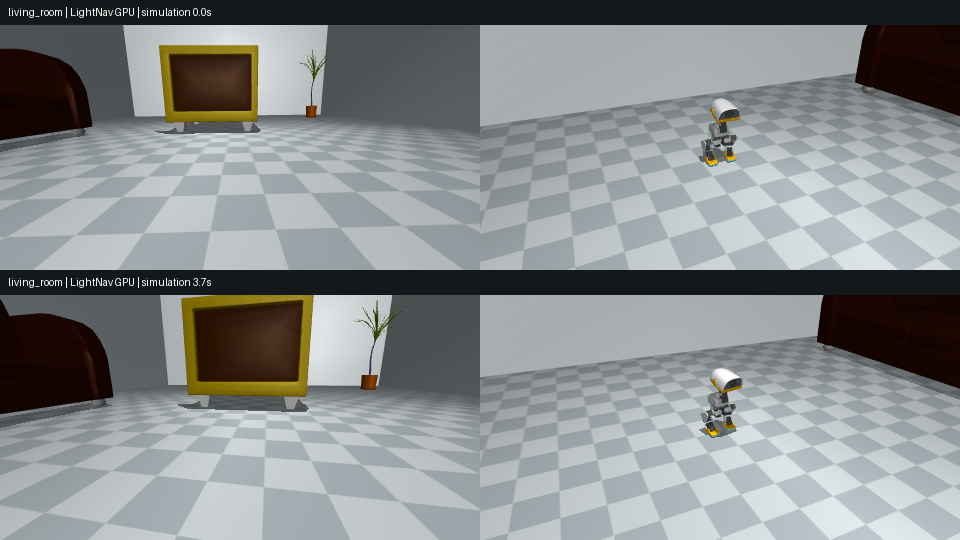

In [9]:
living_report = demonstrate("living_room")

### Собранный коридор

场景：corridor；停止原因：model_stop；真实预测次数：49
仿真时长：13.00 s；推理延迟中位数：110.9 ms
目标中心距离：2.70 → 1.19 m
完整报告：corridor_report.json；导航模型运行在 GPU［图形处理器］。


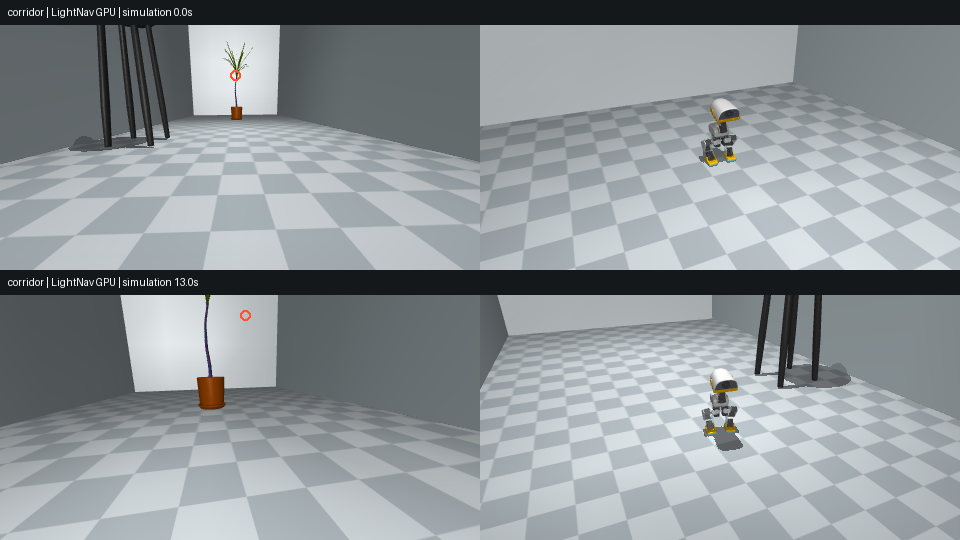

In [10]:
corridor_report = demonstrate("corridor")

## 7. Сравнение реальных траекторий и времени инференса

Синяя линия — реальный путь робота, красная точка — положение цели для измерения.
`model_stop` означает, что модель выдала остановку, `time_limit` — достигнута длительность эксперимента, `fall` — падение;
Выполнение задачи оценивайте по расстоянию до конца пути и видео: сам флаг остановки не означает достижения цели.

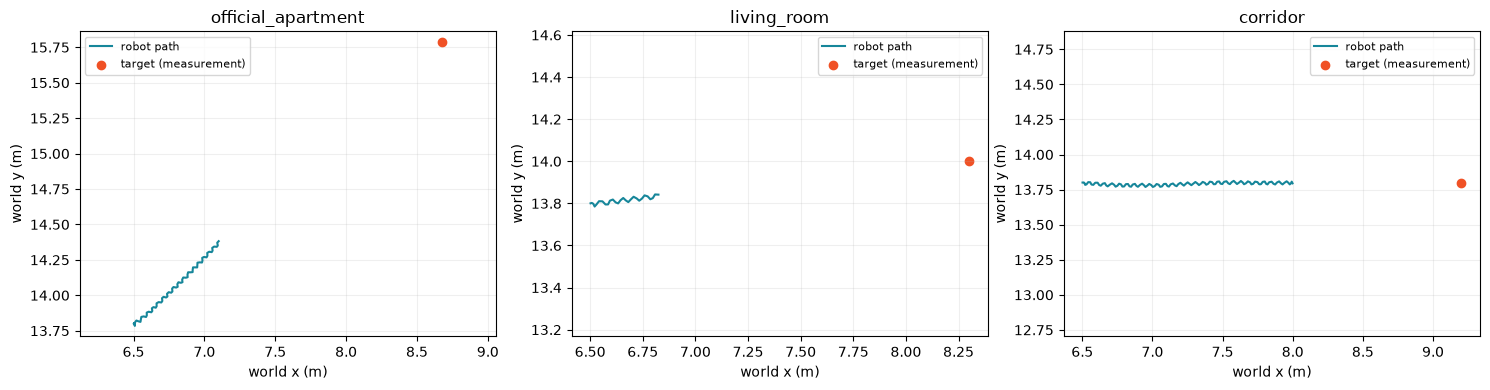

official_apartment: model_stop, predictions=32, distance=2.95 → 2.10 m, median=100.7 ms
living_room: model_stop, predictions=12, distance=1.81 → 1.47 m, median=92.3 ms
corridor: model_stop, predictions=49, distance=2.70 → 1.19 m, median=110.9 ms


In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for axis, (name, scene) in zip(axes, scenes.items()):
    trace = json.loads((OUTPUT / f"{name}_trace.json").read_text())
    axis.plot([p["x"] for p in trace], [p["y"] for p in trace], color="#16869a", label="robot path")
    axis.scatter(*scene["target_xy"], color="#f05125", label="target (measurement)")
    axis.set(title=name, xlabel="world x (m)", ylabel="world y (m)")
    axis.set_aspect("equal", adjustable="datalim")
    axis.grid(alpha=0.2)
    axis.legend(fontsize=8)
plt.tight_layout()
plt.show()
for name, report in reports.items():
    print(f"{name}: {report['termination']}, predictions={report['prediction_count']}, distance={report['initial_target_distance_m']:.2f} → {report['final_target_distance_m']:.2f} m, median={report['median_latency_ms']:.1f} ms")

## 8. Проверка и дальнейшие эксперименты

В следующем раунде можно менять языковое описание, положение мебели или начальную ориентацию и отдельно сравнивать видео, траектории и указания модели.
После изменения сцены заново запустите ячейки построения сцены и последующих экспериментов. Модель, политику ходьбы и физические параметры сначала держите неизменными, чтобы понять, откуда берётся изменение.

[Официальный код LightNav-0](https://github.com/lightorigins/LightNav-0) ·
[Официальное описание симулятора](https://github.com/lightorigins/LightNav-0/blob/main/mujoco_demo/README.md) ·
[Веса модели](https://huggingface.co/LightOriginsHQ/LightNav-0)

In [12]:
import imageio.v2 as imageio
assert set(reports) == set(scenes)
for name, report in reports.items():
    assert report["prediction_count"] > 0
    assert report["trajectory_shape"] == [10, 3]
    assert not report["training"]
    assert (OUTPUT / f"{name}_latest.mp4").stat().st_size > 1000
    with imageio.get_reader(WEB_OUTPUT / f"{name}_latest.mp4") as video:
        assert video.get_meta_data()["duration"] > 0
        assert video.get_data(0).std() > 2, "Первый кадр видео пустой."
    predictions = json.loads((OUTPUT / f"{name}_predictions.json").read_text())
    assert len(predictions) == report["prediction_count"]
summary = OUTPUT / "lesson_summary.json"
summary.write_text(json.dumps(reports, indent=2, ensure_ascii=False), encoding="utf-8")
print("Готово: для всех трёх сцен записаны реальные предсказания модели, видео физической симуляции, пути и время.")
print("Сводка эксперимента:", summary)

完成：三个场景均记录了真实模型预测、物理仿真视频、路径与耗时。
实验汇总： /data/Data14TB/lightnav-recordings/teaching/notebook/lesson_summary.json
